# Integración de datos y análisis exploratorio

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from scientific_audit import evaluate, sha
pd.set_option('display.precision',9)
def audit(phase):
    with threadpool_limits(limits=4): record=evaluate(phase)
    display(pd.DataFrame(record['checks']))
    print('Controles ejecutados:',len(record['checks']),'| Estado:',record['status'])
    print(record['historical_test_warning'])
    return record['detail']
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name))
def figure(name):
    path=ROOT/'reports/figures'/name
    print('Figura:',name,'| SHA-256:',sha(path))
    display(Image(filename=str(path)))
print('Evaluación real de artefactos guardados; no se entrenan clasificadores.')


Evaluación real de artefactos guardados; no se entrenan clasificadores.


## Método y alcance

La unidad de análisis es la persona residente habitual de 6 a 17 años. Se conserva el dataset anual y su orden de filas, vinculados al modelo guardado. El corte 2025 del panel docente se reconstruye por separado: sus valores comunes coinciden por llaves, pero su orden es distinto. Este notebook verifica llaves, variables, transformaciones, población, pesos y particiones. La reconstrucción independiente se documenta en docs/SCIENTIFIC_SYNC.md; esta ejecución no se presenta como una reconstrucción desde raw.

${PROJECT_ROOT}/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,name,passed
0,frozen_models/best_model.joblib,True
1,frozen_models/all_models.joblib,True
2,frozen_models/clustering.joblib,True
3,frozen_data/processed/dataset_enaho_escale_202...,True
4,frozen_data/processed/dataset_modelado_interne...,True
5,dataset_sha256,True
6,analysis_code_sha256,True
7,unique_person_keys,True
8,unique_partition_indices,True
9,group_labels_aligned,True


Controles ejecutados: 41 | Estado: passed
La partición de prueba ya se inspeccionó en la versión anterior. Se conserva para comparabilidad, sin usarla para selección nueva; esta auditoría es retrospectiva y no aporta una prueba externa inédita.


,n_integrated,n_model,n_train,n_test,group_overlap,dataset_sha256
0,23345,16544,13105,3439,0,e46ff2b57a84c34319b94609460a7d7a0972be087a93cb...


,objetivo,n_validos,n_positivos,n_negativos,prevalencia_muestral,prevalencia_ponderada,conglomerados
0,target_rezago,16544,6707,9837,0.405403772,0.403578149,4040
1,target_rezago_2,16544,679,15865,0.041042070,0.038354976,4040
2,target_internet,16544,4294,12250,0.259550290,0.226710658,4040


,etapa,n,excluidos_en_etapa
0,Base integrada residentes6-17,23345,0
1,Edad6-17,23345,0
2,Matriculados P306=1,20058,3287
3,Asistentes P307=1,17807,2251
4,Primaria/secundaria P308A2/3,17080,727
5,Sin CEBA declarado,16544,536
6,Respuesta válida P314A1/2,16544,0
7,Peso individual positivo,16544,0


Figura: raw_eda.png | SHA-256: 410751831470d80bfa7946de218bc4c7ad92965ed3c82dca1fb42179ad3f7910


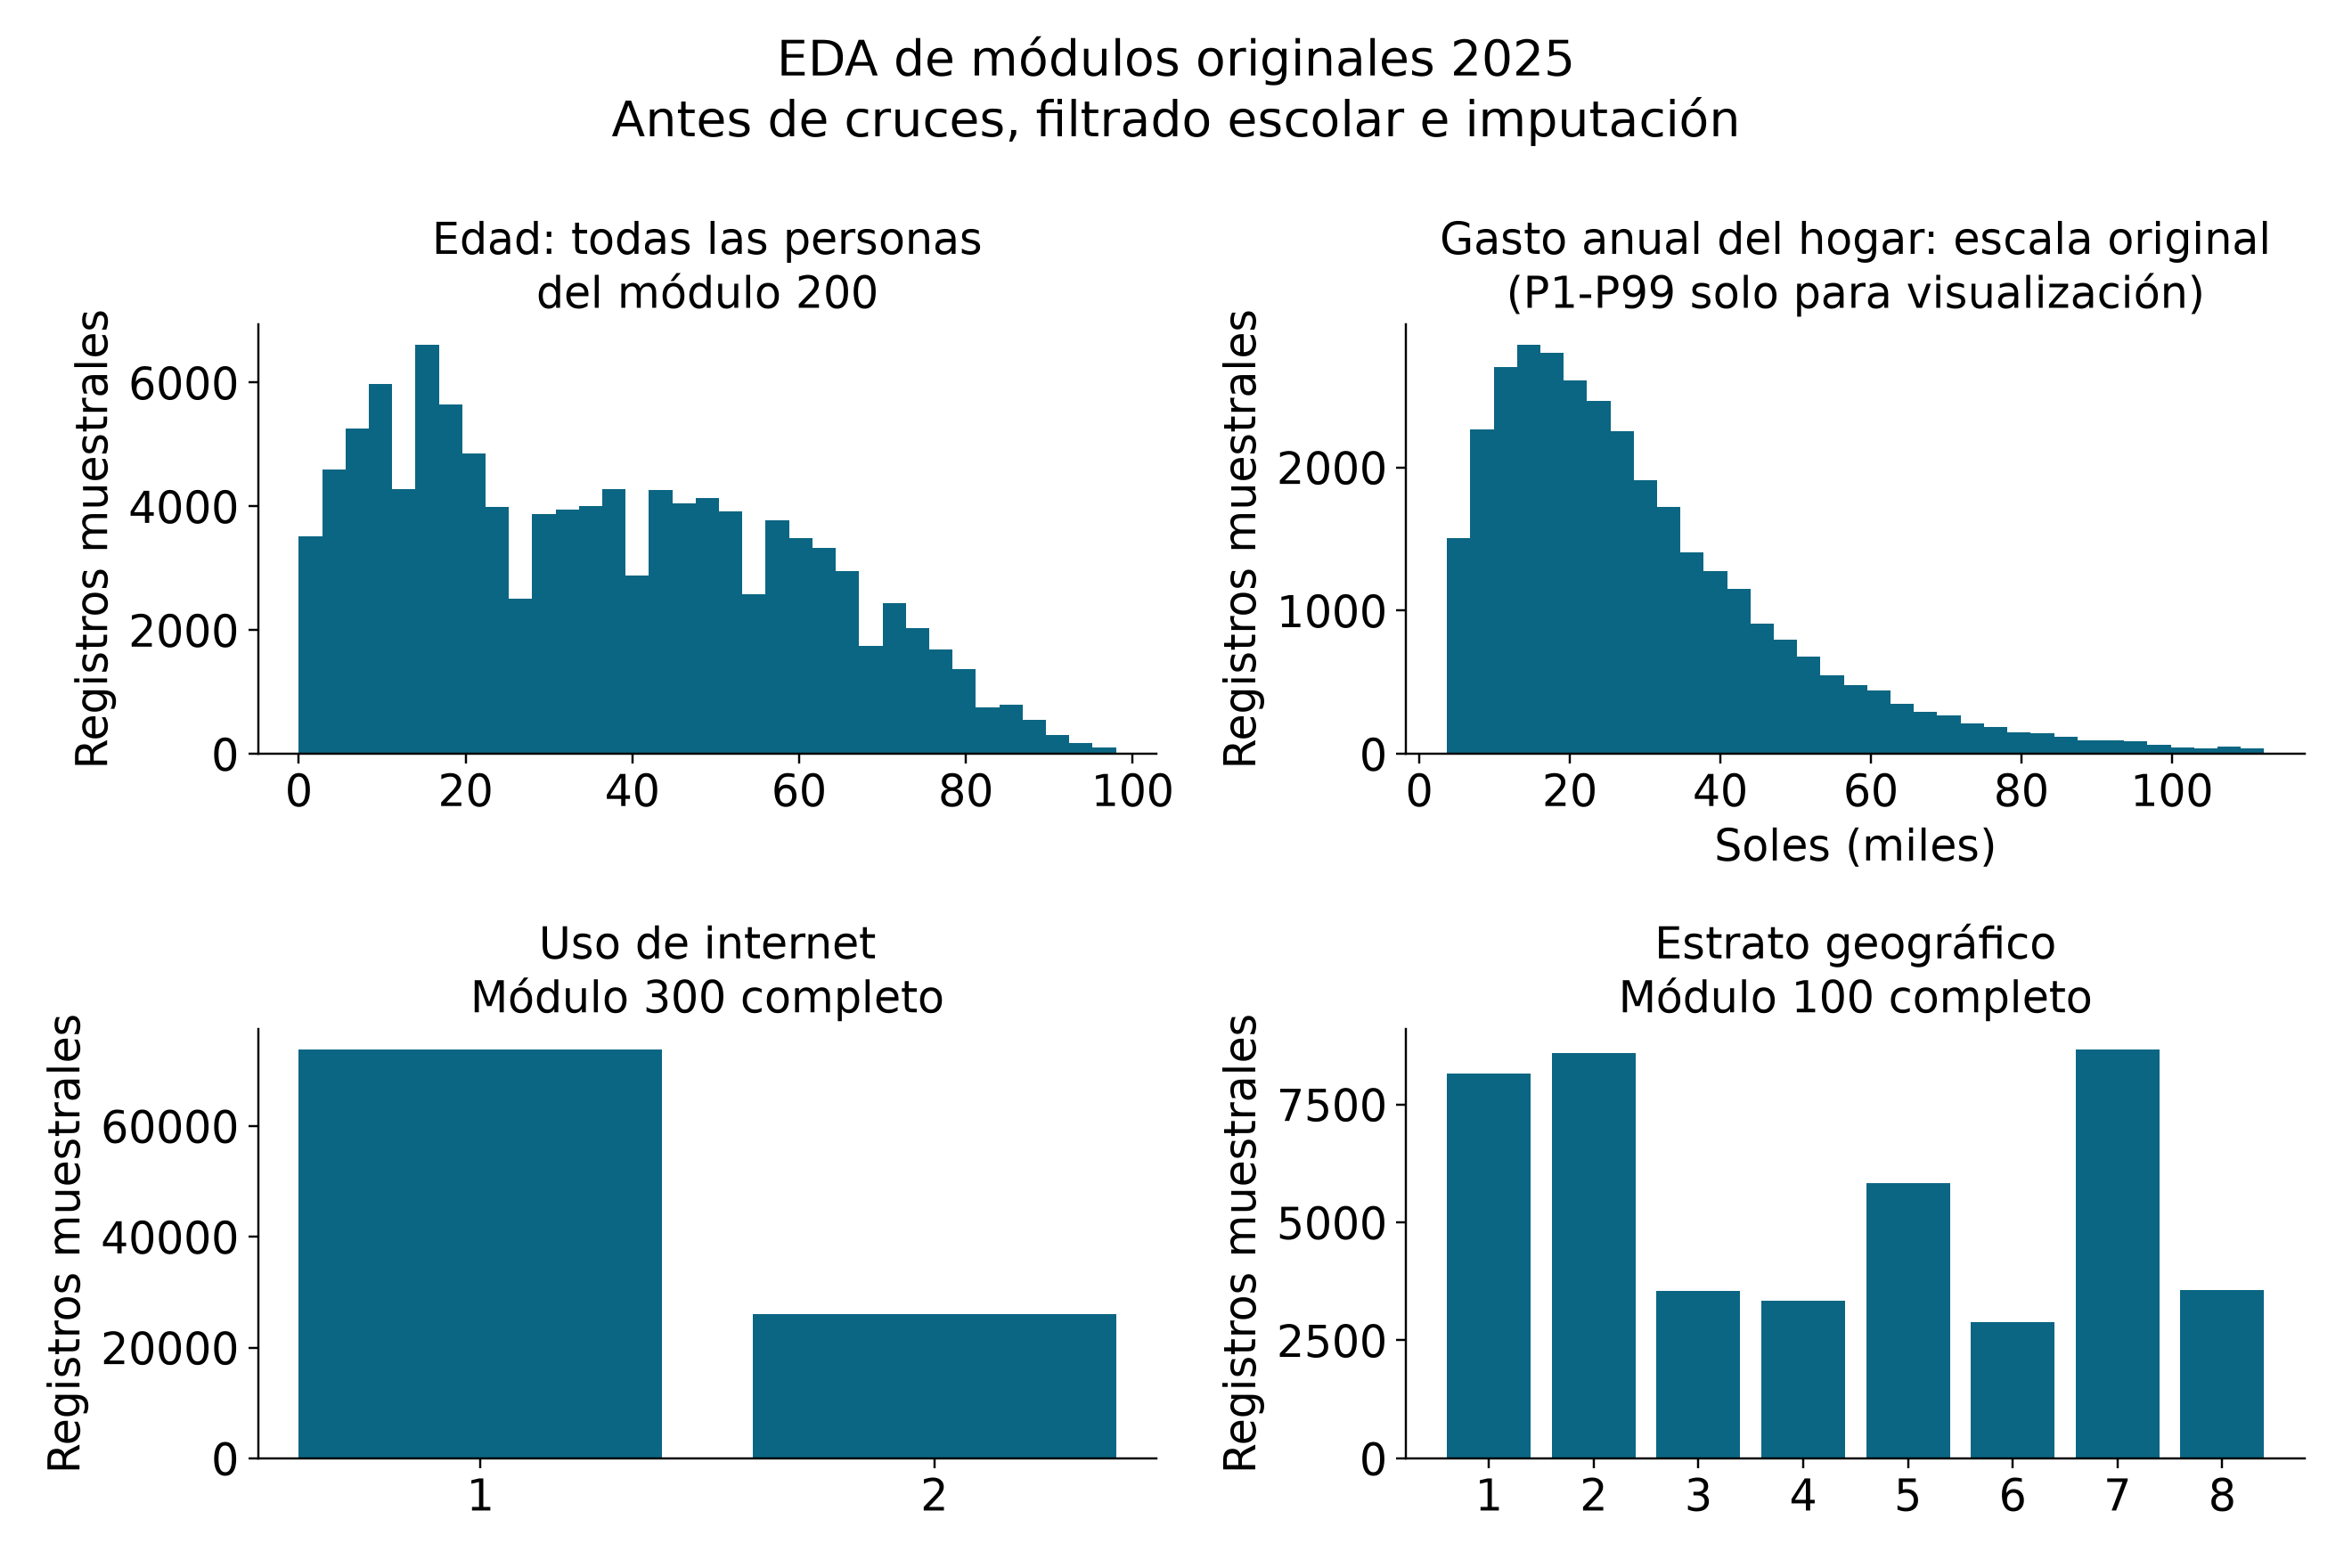

Figura: eda.png | SHA-256: da8ffac9b7074b35d04f539319443586d5b19213b4981e7507f201de728a295e


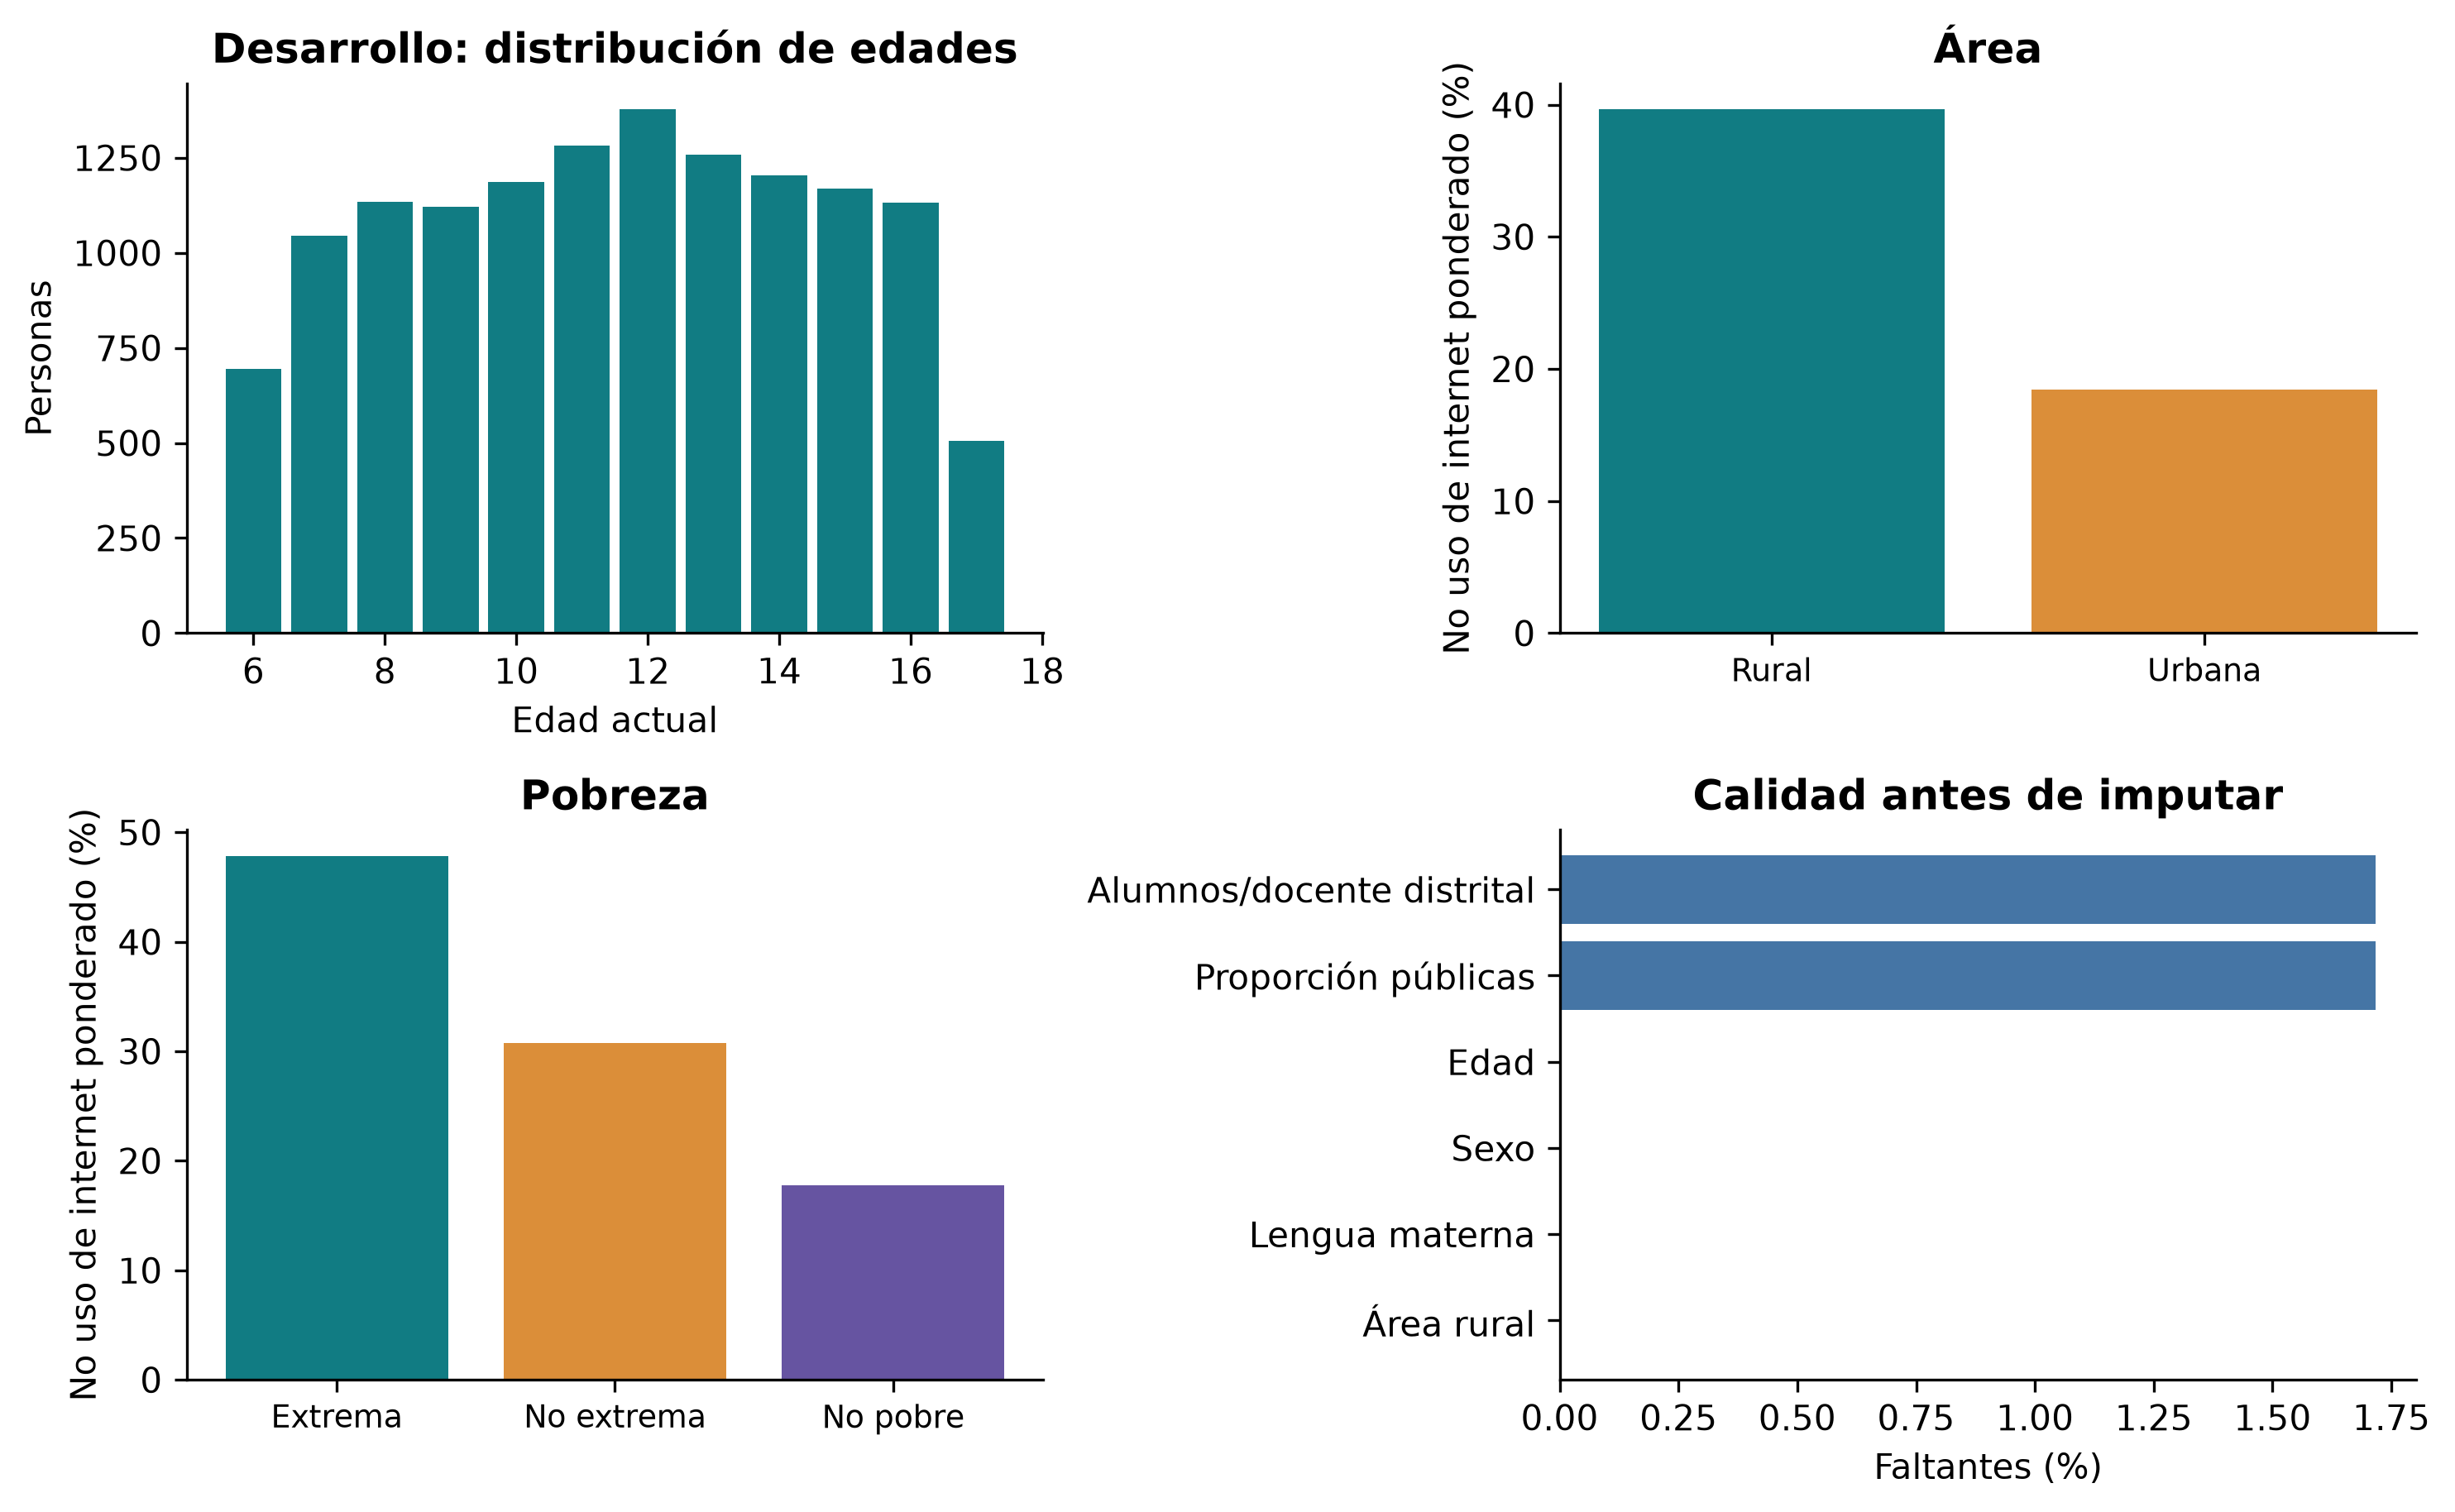

In [2]:
detail=audit('dataset')
display(pd.DataFrame([detail]))
table('target_comparison.csv')
table('population_flow_model.csv')
figure('raw_eda.png')
figure('eda.png')